<a href="https://colab.research.google.com/github/springboardmentor0702-lgtm/Personalized-TED-Talks-Recommendation-System/blob/Suhani/01_TED_Talks_Data_Exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfull!")

Libraries imported successfull!


In [ ]:
import os
import shutil
from glob import glob

folder = "/content/ted_dataset"
os.makedirs(folder, exist_ok=True)

csv_files = glob("/content/*.csv")

for file in csv_files:
    shutil.move(
        file,
        os.path.join(folder, os.path.basename(file))
    )

print("CSV files moved:", len(csv_files))
print(os.listdir(folder))

CSV files moved: 12
['ted_talks_ko.csv', 'ted_talks_pt-br.csv', 'ted_talks_ru.csv', 'ted_talks_zh-tw.csv', 'ted_talks_en.csv', 'ted_talks_es.csv', 'ted_talks_zh-cn.csv', 'ted_talks_it.csv', 'ted_talks_tr.csv', 'ted_talks_he.csv', 'ted_talks_ja.csv', 'ted_talks_fr.csv']


In [ ]:

import pandas as pd

file_path = "/content/ted_dataset/ted_talks_en.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values per column:")
display(df.isnull().sum())

Dataset loaded successfully!
Number of rows and columns: (4005, 19)


,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,native_lang,available_lang,comments,duration,topics,related_talks,url,description,transcript
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523392,2006-02-25,2006-06-27,TED2006,en,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa...",272.0,977,"['alternative energy', 'cars', 'climate change...","{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre..."
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501685,2006-02-22,2006-06-27,TED2006,en,"['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de...",628.0,1190,"['Africa', 'Asia', 'Google', 'demo', 'economic...","{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac..."
2,7,Simplicity sells,David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920832,2006-02-24,2006-06-27,TED2006,en,"['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr...",124.0,1286,"['computers', 'entertainment', 'interface desi...","{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun..."
3,53,Greening the ghetto,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},{0: 'Majora Carter redefined the field of envi...,2664069,2006-02-26,2006-06-27,TED2006,en,"['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es...",219.0,1116,"['MacArthur grant', 'activism', 'business', 'c...",{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,"In an emotionally charged talk, MacArthur-winn...",If you're here today — and I'm very happy that...
4,66,Do schools kill creativity?,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challe...",65051954,2006-02-25,2006-06-27,TED2006,en,"['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs...",4931.0,1164,"['children', 'creativity', 'culture', 'dance',...","{865: 'Bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson makes an entertaining and pro...,Good morning. How are you? (Audience) Good. It...


Column names:
['talk_id', 'title', 'speaker_1', 'all_speakers', 'occupations', 'about_speakers', 'views', 'recorded_date', 'published_date', 'event', 'native_lang', 'available_lang', 'comments', 'duration', 'topics', 'related_talks', 'url', 'description', 'transcript']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4005 entries, 0 to 4004
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   talk_id         4005 non-null   int64  
 1   title           4005 non-null   object 
 2   speaker_1       4005 non-null   object 
 3   all_speakers    4001 non-null   object 
 4   occupations     3483 non-null   object 
 5   about_speakers  3502 non-null   object 
 6   views           4005 non-null   int64  
 7   recorded_date   4004 non-null   object 
 8   published_date  4005 non-null   object 
 9   event           4005 non-null   object 
 10  native_lang     4005 non-null   object 
 11  available_l

,0
talk_id,0
title,0
speaker_1,0
all_speakers,4
occupations,522
about_speakers,503
views,0
recorded_date,1
published_date,0
event,0


In [ ]:
# Missing values in each column
missing = df.isnull().sum()

print("Missing values:")
display(missing[missing > 0].sort_values(ascending=False))

# Duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Duplicate talk IDs
print("Duplicate talk IDs:", df["talk_id"].duplicated().sum())

# Empty transcripts
empty_transcripts = (
    df["transcript"].fillna("").str.strip().eq("")
)

print("Empty transcripts:", empty_transcripts.sum())

Missing values:


,0
comments,655
occupations,522
about_speakers,503
all_speakers,4
recorded_date,1



Duplicate rows: 0
Duplicate talk IDs: 0
Empty transcripts: 0


count     4005.000000
mean      1796.845693
std       1004.008431
min          2.000000
25%        928.000000
50%       1753.000000
75%       2445.000000
max      11121.000000
Name: transcript_words, dtype: float64


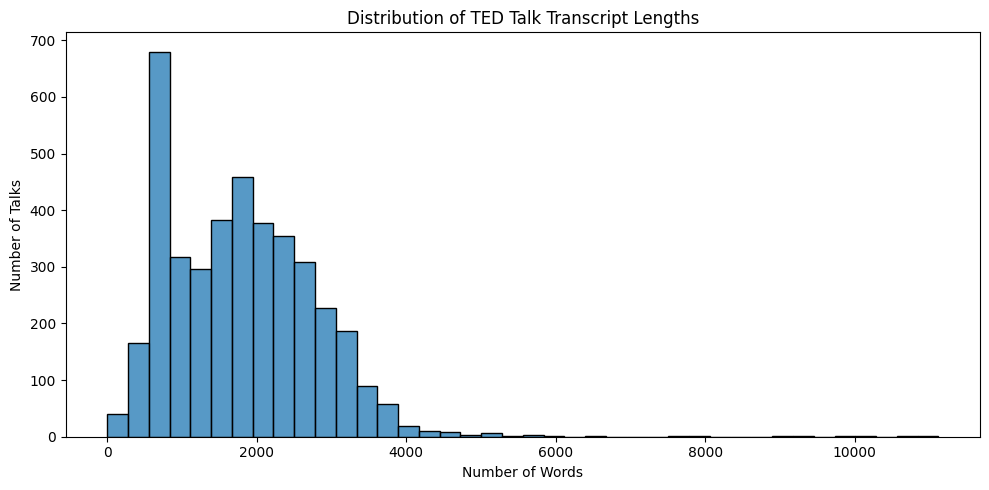

In [ ]:
# Calculate transcript length
df["transcript_words"] = (
    df["transcript"].fillna("").str.split().str.len()
)

print(df["transcript_words"].describe())

plt.figure(figsize=(10, 5))
sns.histplot(df["transcript_words"], bins=40)

plt.title("Distribution of TED Talk Transcript Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Talks")

plt.tight_layout()
plt.show()

In [ ]:
# Check missing and empty text
print("Missing transcripts:",
      df["transcript"].isna().sum())

print("Empty transcripts:",
      df["transcript"].fillna("").str.strip().eq("").sum())

print("Duplicate talk IDs:",
      df["talk_id"].duplicated().sum())

print("Duplicate titles:",
      df["title"].duplicated().sum())

Missing transcripts: 0
Empty transcripts: 0
Duplicate talk IDs: 0
Duplicate titles: 0


In [ ]:
# Create a working copy
df_clean = df.copy()

# Fill missing optional text metadata
text_columns = [
    "title",
    "speaker_1",
    "topics",
    "description",
    "transcript"
]

for col in text_columns:
    df_clean[col] = (
        df_clean[col].fillna("").astype(str).str.strip()
    )

# Remove rows with empty transcripts
df_clean = df_clean[
    df_clean["transcript"].str.len() > 0].copy()

df_clean.reset_index(drop=True, inplace=True)

print("Original rows:", len(df))
print("Rows after removing empty transcripts:", len(df_clean))
print("Preprocessing check complete!")

Original rows: 4005
Rows after removing empty transcripts: 4005
Preprocessing check complete!


In [ ]:
import re

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<[^>]+>", " ", text)  # Remove HTML tags
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

# Create cleaned text columns
for col in ["title", "topics", "description", "transcript"]:
    df_clean[col + "_clean"] = df_clean[col].apply(clean_text)

print("Text cleaning completed!")

display(
    df_clean[
        ["title", "title_clean", "transcript_clean"]
    ].head(3)
)

Text cleaning completed!


,title,title_clean,transcript_clean
0,Averting the climate crisis,averting the climate crisis,thank you so much chris and it s truly a great...
1,The best stats you've ever seen,the best stats you ve ever seen,about years ago i took on the task to teach gl...
2,Simplicity sells,simplicity sells,music the sound of silence simon garfunkel hel...


In [ ]:
df_clean["combined_text"] = (
    df_clean["title_clean"] + " " +
    df_clean["topics_clean"] + " " +
    df_clean["description_clean"] + " " +
    df_clean["transcript_clean"]
)

print("Combined text created!")
print("Example:")
print(df_clean.loc[0, "combined_text"][:500])

Combined text created!
Example:
averting the climate crisis alternative energy cars climate change culture environment global issues science sustainability technology with the same humor and humanity he exuded in an inconvenient truth al gore spells out ways that individuals can address climate change immediately from buying a hybrid to inventing a new hotter brand name for global warming thank you so much chris and it s truly a great honor to have the opportunity to come to this stage twice i m extremely grateful i have been 


In [ ]:
import os

os.makedirs("/content/ted_dataset", exist_ok=True)

df_clean.to_csv(
    "/content/ted_dataset/ted_talks_preprocessed.csv",
    index=False
)

print("Preprocessed dataset saved successfully!")
print("Final shape:", df_clean.shape)

Preprocessed dataset saved successfully!
Final shape: (4005, 25)


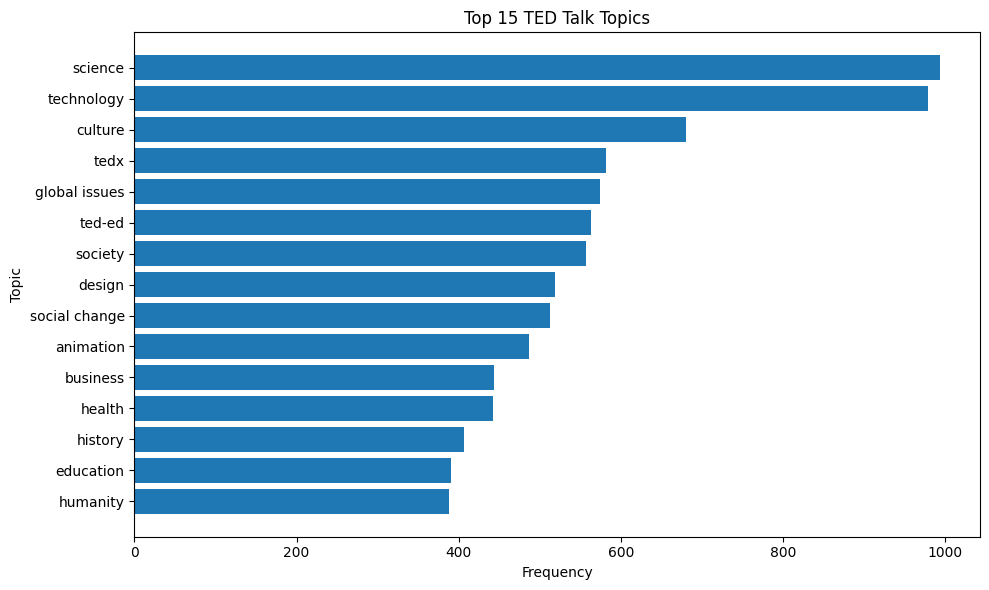

In [ ]:
from collections import Counter
import ast
import matplotlib.pyplot as plt

topic_counts = Counter()

for value in df["topics"].dropna():
    try:
        parsed = ast.literal_eval(value) if isinstance(value, str) else value

        if isinstance(parsed, dict):
            topics = parsed.values()
        elif isinstance(parsed, (list, tuple, set)):
            topics = parsed
        else:
            topics = [parsed]

        for topic in topics:
            if isinstance(topic, str):
                topic_counts[topic.strip().lower()] += 1

    except (ValueError, SyntaxError):
        continue

top_topics = topic_counts.most_common(15)

if top_topics:
    labels, counts = zip(*top_topics)

    plt.figure(figsize=(10, 6))
    plt.barh(labels[::-1], counts[::-1])
    plt.title("Top 15 TED Talk Topics")
    plt.xlabel("Frequency")
    plt.ylabel("Topic")
    plt.tight_layout()
    plt.show()
else:
    print("No topics were extracted. Inspect df['topics'].head().")

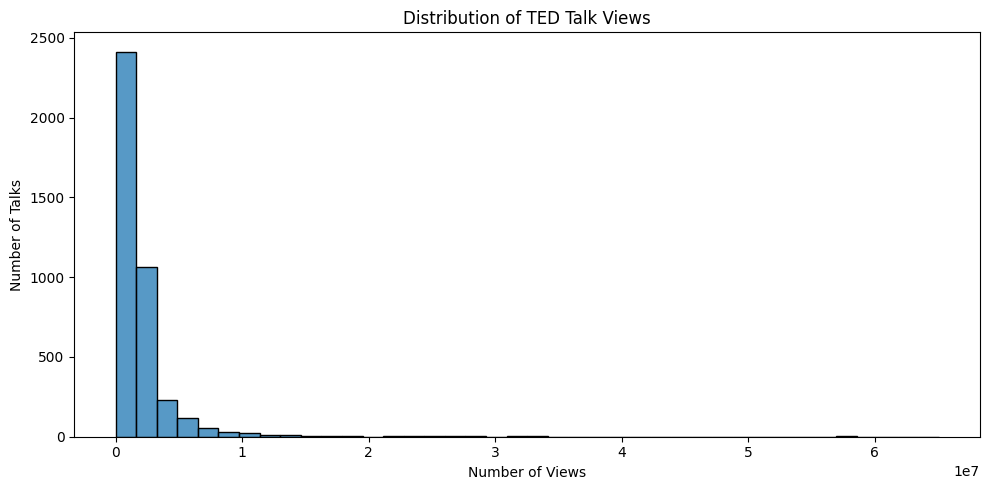

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.histplot(df["views"], bins=40)

plt.title("Distribution of TED Talk Views")
plt.xlabel("Number of Views")
plt.ylabel("Number of Talks")
plt.tight_layout()
plt.show()

In [15]:

import pandas as pd

file_path = "/content/ted_talks_en.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())
import ast

def parse_list_like(value):
    if pd.isna(value):
        return []

    if isinstance(value, (list, tuple, set)):
        return list(value)

    try:
        parsed = ast.literal_eval(str(value))

        if isinstance(parsed, dict):
            return list(parsed.values())
        elif isinstance(parsed, (list, tuple, set)):
            return list(parsed)
        else:
            return [parsed]
    except:
        return []

df["topic_count"] = df["topics"].apply(
    lambda x: len(parse_list_like(x))
)

print("Topic count statistics:")
print(df["topic_count"].describe())

display(
    df[["title", "topics", "topic_count"]].head(10)
)

Dataset loaded successfully!
Number of rows and columns: (4005, 19)


,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,native_lang,available_lang,comments,duration,topics,related_talks,url,description,transcript
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523392,2006-02-25,2006-06-27,TED2006,en,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa...",272.0,977,"['alternative energy', 'cars', 'climate change...","{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre..."
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501685,2006-02-22,2006-06-27,TED2006,en,"['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de...",628.0,1190,"['Africa', 'Asia', 'Google', 'demo', 'economic...","{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac..."
2,7,Simplicity sells,David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920832,2006-02-24,2006-06-27,TED2006,en,"['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr...",124.0,1286,"['computers', 'entertainment', 'interface desi...","{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun..."
3,53,Greening the ghetto,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},{0: 'Majora Carter redefined the field of envi...,2664069,2006-02-26,2006-06-27,TED2006,en,"['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es...",219.0,1116,"['MacArthur grant', 'activism', 'business', 'c...",{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,"In an emotionally charged talk, MacArthur-winn...",If you're here today — and I'm very happy that...
4,66,Do schools kill creativity?,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challe...",65051954,2006-02-25,2006-06-27,TED2006,en,"['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs...",4931.0,1164,"['children', 'creativity', 'culture', 'dance',...","{865: 'Bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson makes an entertaining and pro...,Good morning. How are you? (Audience) Good. It...


Topic count statistics:
count    4005.000000
mean        7.915106
std         3.904362
min         1.000000
25%         5.000000
50%         7.000000
75%        10.000000
max        33.000000
Name: topic_count, dtype: float64


,title,topics,topic_count
0,Averting the climate crisis,"['alternative energy', 'cars', 'climate change...",9
1,The best stats you've ever seen,"['Africa', 'Asia', 'Google', 'demo', 'economic...",11
2,Simplicity sells,"['computers', 'entertainment', 'interface desi...",9
3,Greening the ghetto,"['MacArthur grant', 'activism', 'business', 'c...",9
4,Do schools kill creativity?,"['children', 'creativity', 'culture', 'dance',...",7
5,Behind the design of Seattle's library,"['architecture', 'collaboration', 'culture', '...",5
6,Letting go of God,"['Christianity', 'God', 'atheism', 'comedy', '...",9
7,Let's teach religion -- all religion -- in sch...,"['God', 'atheism', 'brain', 'cognitive science...",8
8,A life of purpose,"['Christianity', 'God', 'culture', 'happiness'...",8
9,My wish: A global day of film,"['TED Prize', 'culture', 'entertainment', 'fil...",10


In [17]:
print("Unique speakers using speaker_1:",
      df["speaker_1"].nunique())

# Extract speakers from all_speakers
all_speakers = []

for value in df["all_speakers"].dropna():
    speakers = parse_list_like(value)

    for speaker in speakers:
        if isinstance(speaker, str):
            all_speakers.append(speaker.strip())

print("Unique speakers using all_speakers:",
      len(set(all_speakers)))
speaker_counts = df["speaker_1"].value_counts()

print("Speakers with multiple talks:")
display(
    speaker_counts[speaker_counts > 1].head(20)
)

Unique speakers using speaker_1: 3274
Unique speakers using all_speakers: 3349
Speakers with multiple talks:


,count
speaker_1,
Alex Gendler,34
Iseult Gillespie,19
Emma Bryce,12
Daniel Finkel,11
Alex Rosenthal,10
Hans Rosling,10
Greg Gage,9
Juan Enriquez,9
Chris Anderson,8


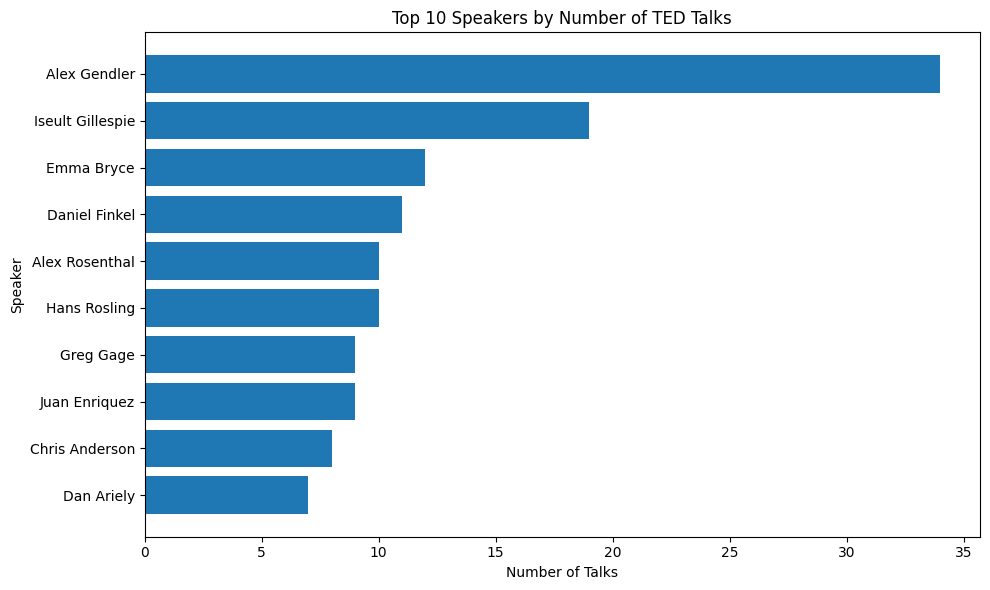

In [18]:
top_speakers = speaker_counts.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_speakers.index[::-1],
    top_speakers.values[::-1]
)

plt.title("Top 10 Speakers by Number of TED Talks")
plt.xlabel("Number of Talks")
plt.ylabel("Speaker")

plt.tight_layout()
plt.show()

In [19]:
text_columns = [
    "title",
    "description",
    "about_speakers",
    "transcript"
]

for col in text_columns:
    df[f"{col}_word_count"] = (
        df[col]
        .fillna("")
        .astype(str)
        .str.split()
        .str.len()
    )

display(
    df[
        [
            "title_word_count",
            "description_word_count",
            "about_speakers_word_count",
            "transcript_word_count"
        ]
    ].describe()
)

,title_word_count,description_word_count,about_speakers_word_count,transcript_word_count
count,4005.000000,4005.000000,4005.000000,4005.000000
mean,6.735331,58.195506,22.399501,1796.845693
std,2.438527,19.430348,16.197742,1004.008431
min,1.000000,9.000000,0.000000,2.000000
25%,5.000000,43.000000,15.000000,928.000000
50%,6.000000,57.000000,22.000000,1753.000000
75%,8.000000,72.000000,28.000000,2445.000000
max,17.000000,143.000000,238.000000,11121.000000


In [21]:
for col in text_columns:
    empty = (
        df[col]
        .fillna("")
        .astype(str)
        .str.strip()
        .eq("")
        .sum()
    )

    print(f"{col}: {empty} empty entries")


    print("Very short transcripts (<100 words):",
      (df["transcript_word_count"] < 100).sum())

print("Very long transcripts (>5000 words):",
      (df["transcript_word_count"] > 5000).sum())

title: 0 empty entries
Very short transcripts (<100 words): 11
description: 0 empty entries
Very short transcripts (<100 words): 11
about_speakers: 503 empty entries
Very short transcripts (<100 words): 11
transcript: 0 empty entries
Very short transcripts (<100 words): 11
Very long transcripts (>5000 words): 22


In [22]:
print("Views statistics:")
print(df["views"].describe())

top_10_views = df.nlargest(10, "views")[
    ["title", "speaker_1", "views"]
]

display(top_10_views)

Views statistics:
count    4.005000e+03
mean     2.148006e+06
std      3.451226e+06
min      0.000000e+00
25%      8.820690e+05
50%      1.375508e+06
75%      2.133110e+06
max      6.505195e+07
Name: views, dtype: float64


,title,speaker_1,views
4,Do schools kill creativity?,Sir Ken Robinson,65051954
1296,Your body language may shape who you are,Amy Cuddy,57074270
2062,This is what happens when you reply to spam email,James Veitch,56932551
646,How great leaders inspire action,Simon Sinek,49730580
796,The power of vulnerability,Brené Brown,47544833
1724,How to speak so that people want to listen,Julian Treasure,41504331
2108,Inside the mind of a master procrastinator,Tim Urban,37976820
1366,"Looks aren't everything. Believe me, I'm a model.",Cameron Russell,33874546
2724,My philosophy for a happy life,Sam Berns,33691484
1898,The next outbreak? We're not ready,Bill Gates,33521780


In [24]:
Q1 = df["views"].quantile(0.25)
Q3 = df["views"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

view_outliers = df[
    (df["views"] < lower_bound) |
    (df["views"] > upper_bound)
]

print("Number of view outliers:", len(view_outliers))
print("Upper outlier threshold:", upper_bound)

print("Duration statistics in seconds:")
print(df["duration"].describe())

Number of view outliers: 393
Upper outlier threshold: 4009671.5
Duration statistics in seconds:
count    4005.000000
mean      724.011236
std       361.775462
min        60.000000
25%       393.000000
50%       738.000000
75%       974.000000
max      3922.000000
Name: duration, dtype: float64


Duration statistics in minutes:
count    4005.000000
mean       12.066854
std         6.029591
min         1.000000
25%         6.550000
50%        12.300000
75%        16.233333
max        65.366667
Name: duration_minutes, dtype: float64
Missing duration: 0
Zero duration: 0


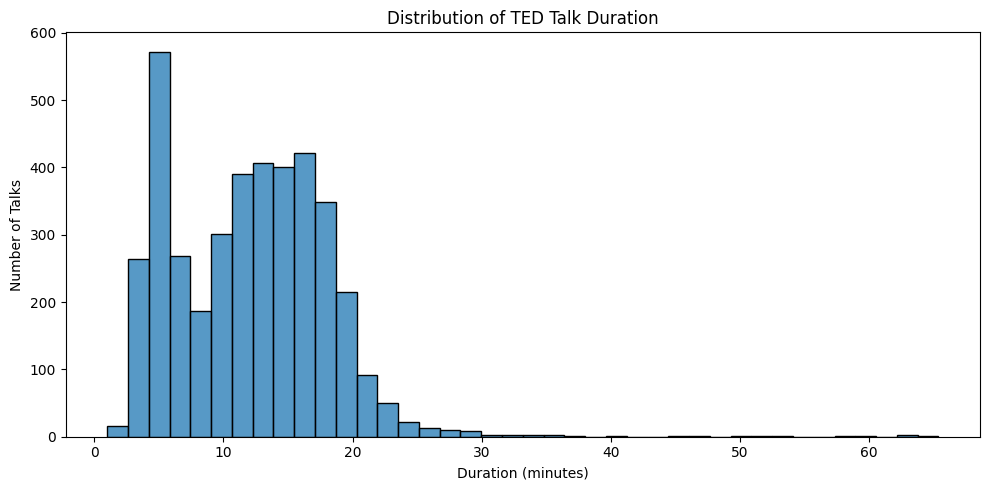

In [26]:
import seaborn as sns
df["duration_minutes"] = df["duration"] / 60

print("Duration statistics in minutes:")
print(df["duration_minutes"].describe())

print("Missing duration:",
      df["duration"].isna().sum())

print("Zero duration:",
      (df["duration"] <= 0).sum())

plt.figure(figsize=(10, 5))

sns.histplot(
    df["duration_minutes"],
    bins=40
)

plt.title("Distribution of TED Talk Duration")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Talks")

plt.tight_layout()
plt.show()

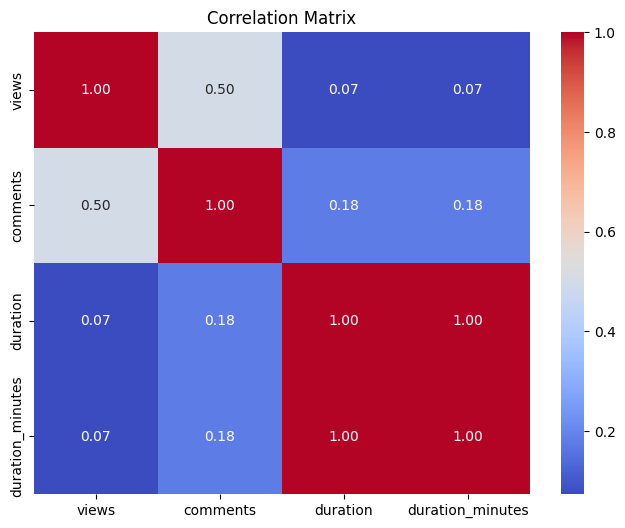

In [55]:
#  Correlation Analysis

numeric_columns = [
    "views",
    "comments",
    "duration",
    "duration_minutes"
]

correlation = df[numeric_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()


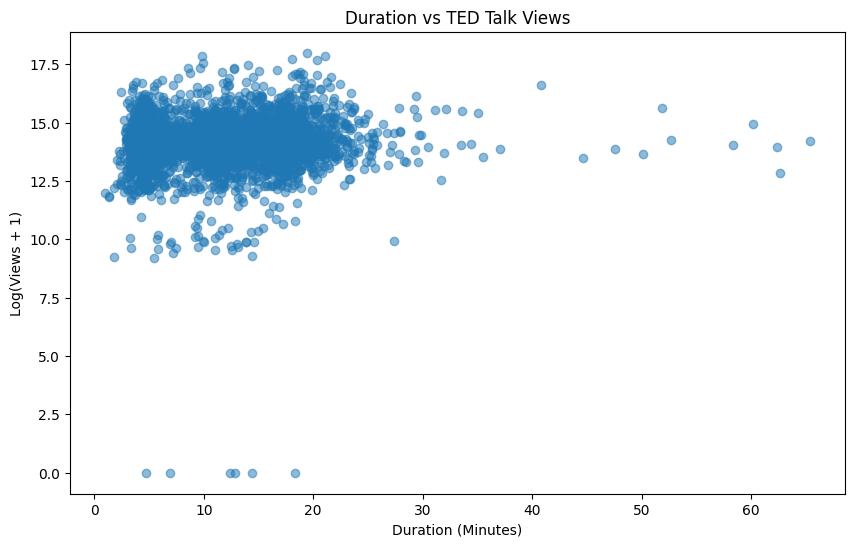

In [57]:

#  Duration vs Views
import numpy as np

# Create the log_views column
df["log_views"] = np.log1p(df["views"])
plt.figure(figsize=(10, 6))

plt.scatter(
    df["duration_minutes"],
    df["log_views"],
    alpha=0.5
)

plt.xlabel("Duration (Minutes)")
plt.ylabel("Log(Views + 1)")
plt.title("Duration vs TED Talk Views")

plt.show()


In [29]:
df["recorded_date"] = pd.to_datetime(
    df["recorded_date"],
    errors="coerce"
)

df["published_date"] = pd.to_datetime(
    df["published_date"],
    errors="coerce"
)

print(df[["recorded_date", "published_date"]].dtypes)

print("Earliest recorded date:",
      df["recorded_date"].min())

print("Latest recorded date:",
      df["recorded_date"].max())

print("Earliest published date:",
      df["published_date"].min())

print("Latest published date:",
      df["published_date"].max())

yearly_publications = (
    df["published_date"]
    .dt.year
    .value_counts()
    .sort_index()
)

display(yearly_publications)

recorded_date     datetime64[ns]
published_date    datetime64[ns]
dtype: object
Earliest recorded date: 1984-02-02 00:00:00
Latest recorded date: 2020-04-30 00:00:00
Earliest published date: 2006-06-27 00:00:00
Latest published date: 2020-04-30 00:00:00


,count
published_date,
2006,49
2007,119
2008,185
2009,215
2010,230
2011,255
2012,303
2013,242
2014,240


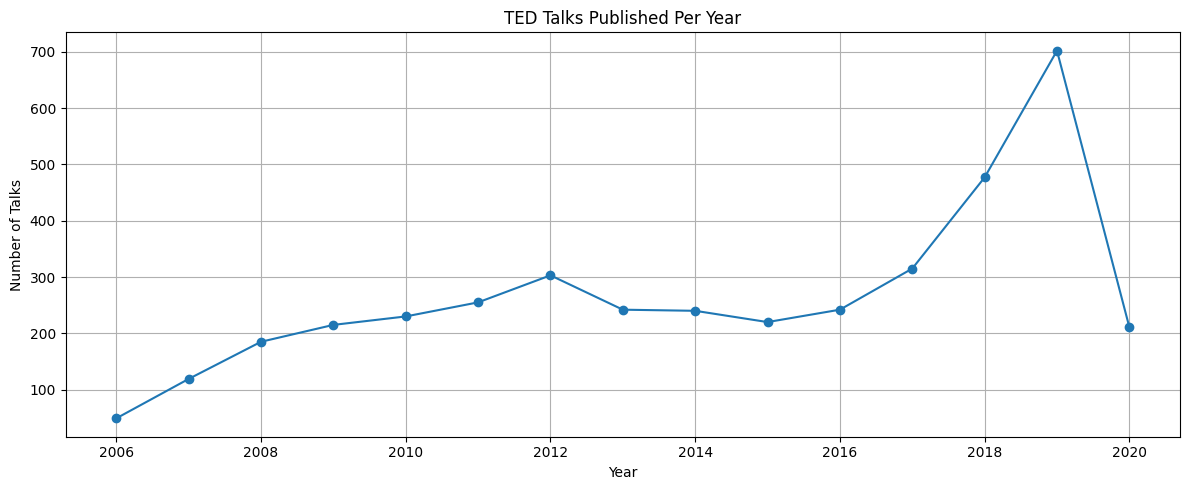

In [30]:
plt.figure(figsize=(12, 5))

plt.plot(
    yearly_publications.index,
    yearly_publications.values,
    marker="o"
)

plt.title("TED Talks Published Per Year")
plt.xlabel("Year")
plt.ylabel("Number of Talks")

plt.grid(True)
plt.tight_layout()
plt.show()

In [31]:
print("Native language distribution:")

display(
    df["native_lang"]
    .value_counts()
    .head(20)
)

Native language distribution:


,count
native_lang,
en,3957
es,27
fr,9
ja,3
hi,2
de,1
pt,1
ko,1
pt-br,1


In [33]:
available_languages = []

for value in df["available_lang"].dropna():
    languages = parse_list_like(value)

    for language in languages:
        if isinstance(language, str):
            available_languages.append(language.strip())

language_counts = pd.Series(
    available_languages
).value_counts()

print("Top available languages:")
display(language_counts.head(20))


print("Missing native language:",
      df["native_lang"].isna().sum())

print("Missing available language:",
      df["available_lang"].isna().sum())

Top available languages:


,count
en,4005
es,3915
pt-br,3899
fr,3863
ar,3841
zh-tw,3818
zh-cn,3788
ko,3755
ru,3676
tr,3610


Missing native language: 0
Missing available language: 0


In [34]:
event_counts = df["event"].value_counts()

print("Top 15 events:")
display(event_counts.head(15))

Top 15 events:


,count
event,
TED-Ed,556
TED2017,96
TED2018,96
TED2019,91
TED2014,84
TED2009,81
TED2016,75
TED2015,75
TED2013,75


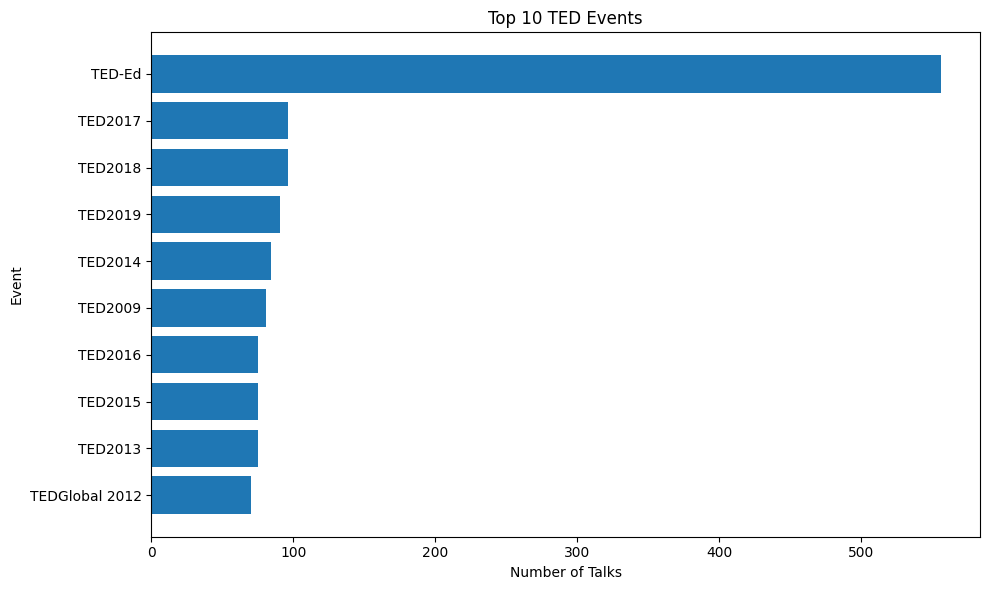

In [35]:
top_events = event_counts.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_events.index[::-1],
    top_events.values[::-1]
)

plt.title("Top 10 TED Events")
plt.xlabel("Number of Talks")
plt.ylabel("Event")

plt.tight_layout()
plt.show()

In [40]:
print("Comments statistics:")
print(df["comments"].describe())

top_comments = df.nlargest(
    10,
    "comments"
)[
    ["title", "speaker_1", "comments"]
]

display(top_comments)

Comments statistics:
count    3350.000000
mean      161.997015
std       268.838922
min         0.000000
25%        38.000000
50%        89.000000
75%       188.000000
max      6449.000000
Name: comments, dtype: float64


,title,speaker_1,comments
94,Militant atheism,Richard Dawkins,6449.0
4,Do schools kill creativity?,Sir Ken Robinson,4931.0
617,Science can answer moral questions,Sam Harris,3424.0
1735,How do you explain consciousness?,David Chalmers,3006.0
197,My stroke of insight,Jill Bolte Taylor,2984.0
1296,Your body language may shape who you are,Amy Cuddy,2633.0
911,Taking imagination seriously,Janet Echelman,2529.0
799,On reading the Koran,Lesley Hazleton,2463.0
631,The danger of science denial,Michael Specter,2366.0
796,The power of vulnerability,Brené Brown,2209.0


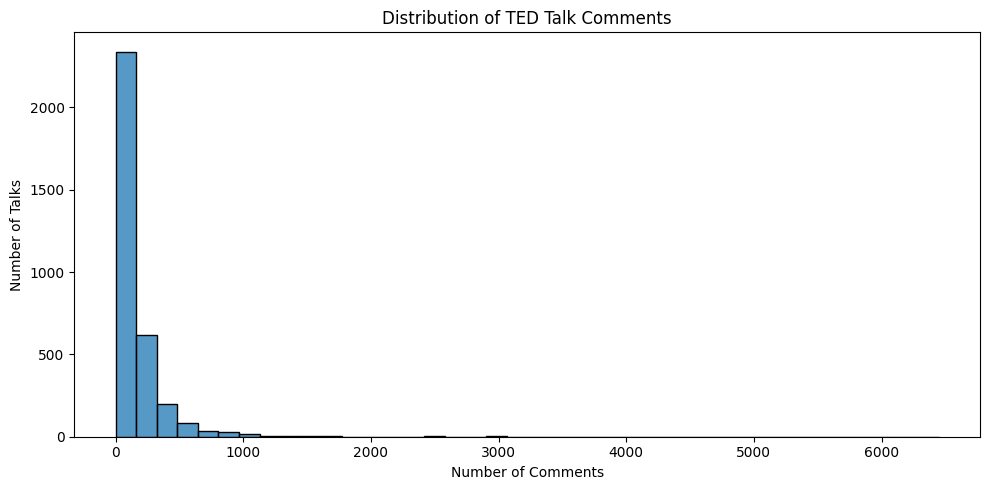

In [41]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["comments"].dropna(),
    bins=40
)

plt.title("Distribution of TED Talk Comments")
plt.xlabel("Number of Comments")
plt.ylabel("Number of Talks")

plt.tight_layout()
plt.show()

In [42]:
Q1 = df["comments"].quantile(0.25)
Q3 = df["comments"].quantile(0.75)

IQR = Q3 - Q1

upper_comment_bound = Q3 + 1.5 * IQR

comment_outliers = df[
    df["comments"] > upper_comment_bound
]

print(
    "Number of comment outliers:",
    len(comment_outliers)
)

print(
    "Upper outlier threshold:",
    upper_comment_bound
)

Number of comment outliers: 261
Upper outlier threshold: 413.0


In [44]:
df["related_talk_count"] = df["related_talks"].apply(
    lambda x: len(parse_list_like(x))
)

print("Related talks statistics:")
print(df["related_talk_count"].describe())

display(
    df[
        ["title", "related_talks", "related_talk_count"]
    ].head(10)
)

Related talks statistics:
count    4005.000000
mean        5.971286
std         0.270834
min         1.000000
25%         6.000000
50%         6.000000
75%         6.000000
max         6.000000
Name: related_talk_count, dtype: float64


,title,related_talks,related_talk_count
0,Averting the climate crisis,"{243: 'New thinking on the climate crisis', 54...",6
1,The best stats you've ever seen,"{2056: ""Own your body's data"", 2296: 'A visual...",6
2,Simplicity sells,"{1725: '10 top time-saving tech tips', 2274: '...",6
3,Greening the ghetto,{1041: '3 stories of local eco-entrepreneurshi...,6
4,Do schools kill creativity?,"{865: 'Bring on the learning revolution!', 173...",6
5,Behind the design of Seattle's library,{750: 'Building a theater that remakes itself'...,6
6,Letting go of God,"{22: 'Why people believe weird things', 94: ""L...",6
7,Let's teach religion -- all religion -- in sch...,"{71: 'A life of purpose', 2011: 'Is religion g...",6
8,A life of purpose,"{94: ""Let's teach religion -- all religion -- ...",6
9,My wish: A global day of film,{2228: 'How virtual reality can create the ult...,6


In [46]:
print(
    "Talks with related talks:",
    (df["related_talk_count"] > 0).sum()
)

print(
    "Talks without related talks:",
    (df["related_talk_count"] == 0).sum()
)

print(df["related_talks"].dropna().iloc[0])

Talks with related talks: 4005
Talks without related talks: 0
{243: 'New thinking on the climate crisis', 547: 'The business logic of sustainability', 2093: 'The state of the climate — and what we might do about it', 54715: 'How we can turn the tide on climate', 29968: 'The most important thing you can do to fight climate change: talk about it', 2339: "Climate change is happening. Here's how we adapt"}


In [47]:
missing_summary = (
    df.isnull()
    .sum()
    .sort_values(ascending=False)
)

display(
    missing_summary[missing_summary > 0]
)

,0
comments,655
occupations,522
about_speakers,503
all_speakers,4
recorded_date,1


In [48]:
print("Duplicate complete rows:",
      df.duplicated().sum())

print("Duplicate talk IDs:",
      df["talk_id"].duplicated().sum())

Duplicate complete rows: 0
Duplicate talk IDs: 0


In [50]:
df_clean = df.copy()

text_columns = [
    "title",
    "speaker_1",
    "topics",
    "description",
    "about_speakers",
    "transcript"
]

for col in text_columns:
    df_clean[col] = (
        df_clean[col]
        .fillna("")
        .astype(str)
        .str.strip()
    )

In [51]:
import re

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

for col in [
    "title",
    "topics",
    "description",
    "transcript"
]:
    df_clean[col + "_clean"] = (
        df_clean[col].apply(clean_text)
    )

In [52]:

df_clean["combined_text"] = (
    df_clean["title_clean"] + " " +
    df_clean["topics_clean"] + " " +
    df_clean["description_clean"] + " " +
    df_clean["transcript_clean"]
)

In [53]:
df_clean = df_clean[
    df_clean["transcript_clean"].str.len() > 0
].copy()

df_clean.reset_index(drop=True, inplace=True)

print("Final cleaned dataset:", df_clean.shape)

Final cleaned dataset: (4005, 31)


In [54]:
import os

os.makedirs("/content/ted_dataset", exist_ok=True)

output_path = (
    "/content/ted_dataset/"
    "ted_talks_preprocessed.csv"
)

df_clean.to_csv(
    output_path,
    index=False
)

print("Saved successfully!")
print(output_path)

Saved successfully!
/content/ted_dataset/ted_talks_preprocessed.csv
